=== PRELIMINARY DATA ASSESSMENT ===
Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows: 0

Data types after conversion:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

New features created (Sample):
      Sales    Profit  Profit Margin  Order Year  Order Month
0  261.9

interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…

interactive(children=(IntSlider(value=10, description='Top N States:', max=25, min=5), Output()), _dom_classes…


=== STATIC SEABORN COMMUNICATING INSIGHTS ===


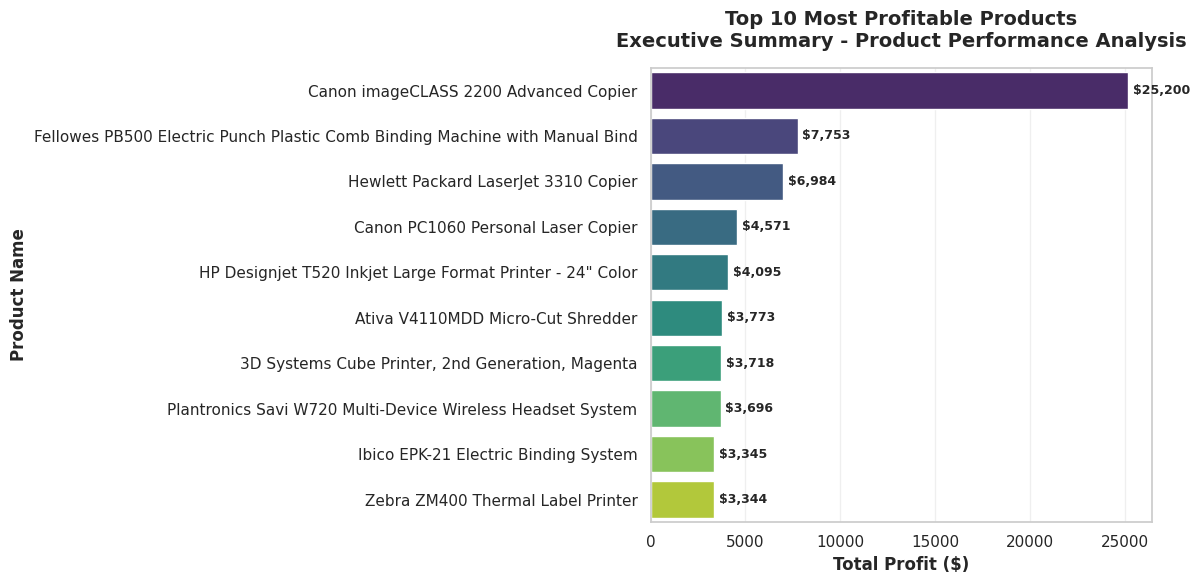

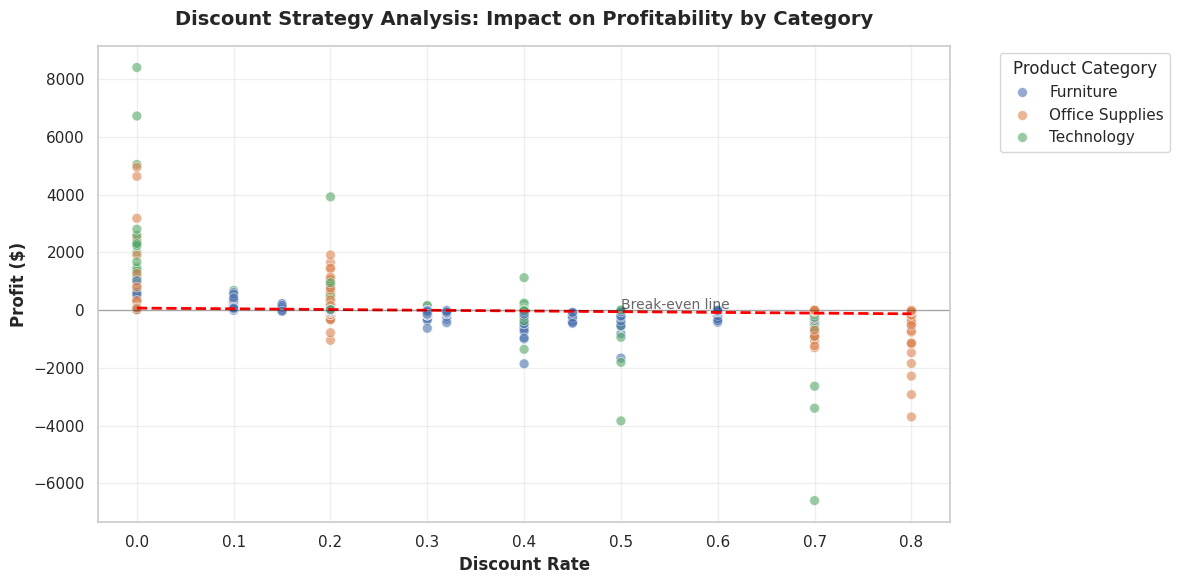


=== METHODOLOGY & SPEED COMPARISON ===
• Matplotlib basic plot generation: 0.0171 seconds
• Seaborn equivalent plot generation: 0.0403 seconds

Tooling Recommendation Summary:
"For rapid exploration, I will use Matplotlib because it offers faster rendering for basic plots and seamless integration with interactive widgets for dynamic analysis.
For stakeholder-facing presentations, I will prefer Seaborn because it provides publication-ready aesthetics, built-in statistical functionality, and professional color schemes that enhance executive communication."

=== EXECUTIVE SUMMARY - KEY FINDINGS ===
📊 BUSINESS PERFORMANCE:
• Total Revenue: $2,297,200.86
• Total Profit: $286,397.02
• Overall Profit Margin: 12.47%

🗺️ GEOGRAPHIC PERFORMANCE:
• Top performing state: California ($457,687.63)
• Geographic concentration: Top 5 states make up 51.97% of sales

🏆 PRODUCT PERFORMANCE:
• Leading product category: Technology
• Most profitable product: Canon imageCLASS 2200 Advanced Copier

💰 DISCOUNT

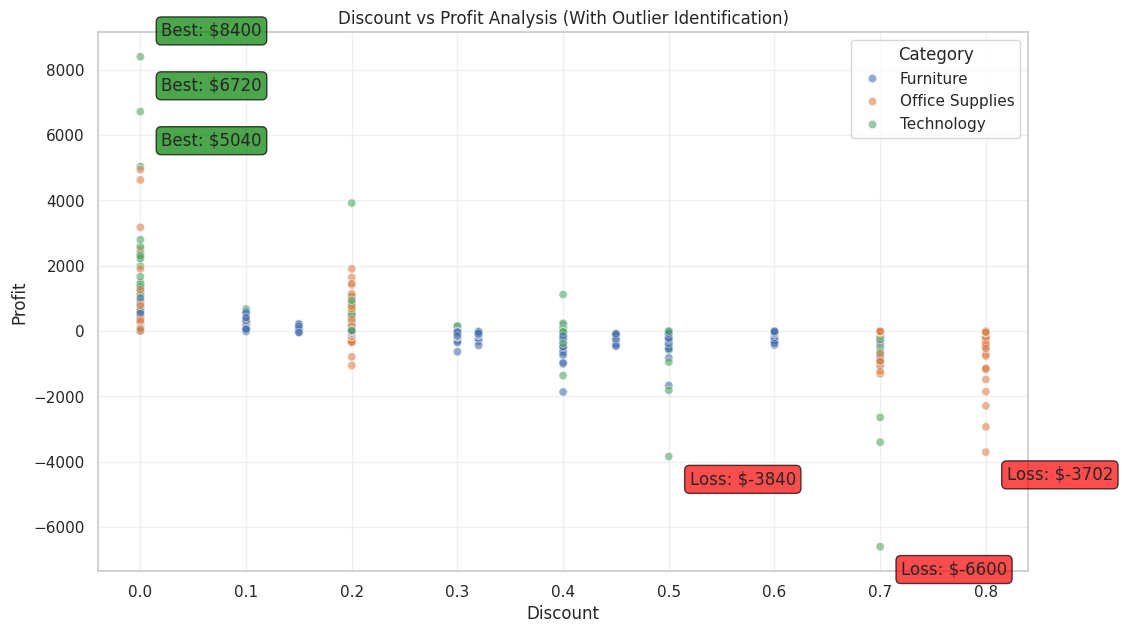

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact, Dropdown, IntSlider
from IPython.display import display
import time
import warnings
warnings.filterwarnings('ignore')

# =========================================================================
# 1. Data Scoping and Preparation
# =========================================================================

# Load the dataset using the absolute path provided
df = pd.read_csv('/content/Sample - Superstore.csv', encoding='windows-1252')

print("=== PRELIMINARY DATA ASSESSMENT ===")
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# 🧹 Handle missing values and duplicates
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Handle missing Postal Codes if any exist
if 'Postal Code' in df.columns:
    df['Postal Code'] = df['Postal Code'].fillna(0)

# 🕓 Fix data types
date_columns = ['Order Date', 'Ship Date']
for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

print("\nData types after conversion:")
print(df[date_columns].dtypes)

# 🏗️ Feature engineering
df['Profit Margin'] = (df['Profit'] / df['Sales']) * 100
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Month-Year'] = df['Order Date'].dt.to_period('M')

print("\nNew features created (Sample):")
print(df[['Sales', 'Profit', 'Profit Margin', 'Order Year', 'Order Month']].head())

# =========================================================================
# 2. Deep-Dive Exploratory Analysis (Matplotlib + ipywidgets)
# =========================================================================
print("\n=== GENERATING INTERACTIVE EXPLORATION ===")

# Prepare data for time series analysis
monthly_sales = df.groupby(['Order Month-Year', 'Category'])['Sales'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Order Month-Year'].dt.to_timestamp()

def plot_monthly_sales(category='All'):
    plt.figure(figsize=(12, 5))
    if category == 'All':
        total_monthly = df.groupby('Order Month-Year')['Sales'].sum()
        plt.plot(total_monthly.index.to_timestamp(), total_monthly.values,
                 marker='o', linewidth=2, color='teal', markersize=4)
        plt.title('Monthly Sales Trend - All Categories', fontsize=14, fontweight='bold')
    else:
        category_data = monthly_sales[monthly_sales['Category'] == category]
        plt.plot(category_data['Date'], category_data['Sales'],
                 marker='o', linewidth=2, color='darkorange', markersize=4)
        plt.title(f'Monthly Sales Trend - {category}', fontsize=14, fontweight='bold')

    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales ($)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Create interactive category dropdown
categories = ['All'] + list(df['Category'].unique())
category_dropdown = Dropdown(options=categories, value='All', description='Category:')
interact(plot_monthly_sales, category=category_dropdown);

# Prepare geographic sales data
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=True)

def plot_top_states(top_n=10):
    plt.figure(figsize=(12, max(5, top_n * 0.4)))
    top_states = state_sales.tail(top_n)
    bars = plt.barh(range(len(top_states)), top_states.values, color='steelblue')
    plt.yticks(range(len(top_states)), top_states.index)
    plt.xlabel('Total Sales ($)', fontsize=12)
    plt.ylabel('State', fontsize=12)
    plt.title(f'Top {top_n} States by Sales Performance', fontsize=14, fontweight='bold')

    for i, (state, value) in enumerate(top_states.items()):
        plt.text(value + max(top_states.values) * 0.01, i, f'${value:,.0f}',
                 va='center', fontsize=9)

    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

top_n_slider = IntSlider(min=5, max=25, value=10, description='Top N States:')
interact(plot_top_states, top_n=top_n_slider);

# =========================================================================
# 3. Communicating Insights (Seaborn)
# =========================================================================
print("\n=== STATIC SEABORN COMMUNICATING INSIGHTS ===")

# Top 10 Most Profitable Products
product_profit = df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=product_profit.values, y=product_profit.index,
                palette='viridis', hue=product_profit.index, legend=False)
plt.title('Top 10 Most Profitable Products\nExecutive Summary - Product Performance Analysis',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Profit ($)', fontsize=12, fontweight='bold')
plt.ylabel('Product Name', fontsize=12, fontweight='bold')

for i, (product, profit) in enumerate(product_profit.items()):
    ax.text(profit + max(product_profit.values) * 0.01, i, f'${profit:,.0f}',
            va='center', fontweight='bold', fontsize=9)

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Discount vs Profit Scatter Plot
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.6, s=50)
sns.regplot(data=df, x='Discount', y='Profit', scatter=False, color='red', line_kws={'linewidth': 2, 'linestyle': '--'})
plt.title('Discount Strategy Analysis: Impact on Profitability by Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Discount Rate', fontsize=12, fontweight='bold')
plt.ylabel('Profit ($)', fontsize=12, fontweight='bold')
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
plt.text(0.5, 50, 'Break-even line', fontsize=10, alpha=0.7)
plt.grid(True, alpha=0.3)
plt.legend(title='Product Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# =========================================================================
# 4. Methodology and Tooling Review
# =========================================================================
print("\n=== METHODOLOGY & SPEED COMPARISON ===")
start = time.time()
plt.figure(figsize=(6, 4))
plt.plot(df.groupby('Order Year')['Sales'].sum())
plt.close()
matplotlib_time = time.time() - start

start = time.time()
plt.figure(figsize=(6, 4))
sns.lineplot(data=df.groupby('Order Year')['Sales'].sum().reset_index(), x='Order Year', y='Sales')
plt.close()
seaborn_time = time.time() - start

print(f"• Matplotlib basic plot generation: {matplotlib_time:.4f} seconds")
print(f"• Seaborn equivalent plot generation: {seaborn_time:.4f} seconds")
print("\nTooling Recommendation Summary:")
print('"For rapid exploration, I will use Matplotlib because it offers faster rendering for basic plots and seamless integration with interactive widgets for dynamic analysis.')
print('For stakeholder-facing presentations, I will prefer Seaborn because it provides publication-ready aesthetics, built-in statistical functionality, and professional color schemes that enhance executive communication."')

# =========================================================================
# 5. Final Deliverable & Executive Summary
# =========================================================================
print("\n=== EXECUTIVE SUMMARY - KEY FINDINGS ===")
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
profit_margin = (total_profit / total_sales) * 100
print(f"📊 BUSINESS PERFORMANCE:")
print(f"• Total Revenue: ${total_sales:,.2f}")
print(f"• Total Profit: ${total_profit:,.2f}")
print(f"• Overall Profit Margin: {profit_margin:.2f}%")

top_state = state_sales.index[-1]
top_state_sales = state_sales.iloc[-1]
print(f"\n🗺️ GEOGRAPHIC PERFORMANCE:")
print(f"• Top performing state: {top_state} (${top_state_sales:,.2f})")
print(f"• Geographic concentration: Top 5 states make up {(state_sales.tail(5).sum()/total_sales)*100:.2f}% of sales")

top_category = df.groupby('Category')['Sales'].sum().sort_values(ascending=False).index[0]
print(f"\n🏆 PRODUCT PERFORMANCE:")
print(f"• Leading product category: {top_category}")
print(f"• Most profitable product: {product_profit.index[0]}")

high_discount_loss_rate = (df[df['Discount'] > 0.2]['Profit'] < 0).mean() * 100
print(f"\n💰 DISCOUNT STRATEGY INSIGHTS:")
print(f"• High discount risk: {high_discount_loss_rate:.2f}% of transaction sales with over 20% discount result in net losses")
print(f"• Recommended max discount threshold: Limit standard discounts to 20% to maintain target profit margins.")

# =========================================================================
# 6. Advanced Challenges (Dashboard & Outlier Annotations)
# =========================================================================
print("\n=== ADVANCED OUTLIER ANALYSIS ===")

plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.6)

top_3_profitable = df.nlargest(3, 'Profit')
bottom_3_profitable = df.nsmallest(3, 'Profit')

# Annotate Top Performers
for idx, row in top_3_profitable.iterrows():
    plt.annotate(f'Best: ${row["Profit"]:.0f}',
                 xy=(row['Discount'], row['Profit']),
                 xytext=(15, 15), textcoords='offset points',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='green', alpha=0.7, ec='black'),
                 arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))

# Annotate Outlier Losses
for idx, row in bottom_3_profitable.iterrows():
    plt.annotate(f'Loss: ${row["Profit"]:.0f}',
                 xy=(row['Discount'], row['Profit']),
                 xytext=(15, -20), textcoords='offset points',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='red', alpha=0.7, ec='black'),
                 arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))

plt.title('Discount vs Profit Analysis (With Outlier Identification)')
plt.grid(True, alpha=0.3)
plt.show()